In [ ]:
from __future__ import annotations

from langgraph.graph import StateGraph, END
from langgraph.graph.state import CompiledStateGraph

from state import OrchestratorState, Task, TaskStatus


def planner_node(state: OrchestratorState) -> dict:
    task = state["tasks"]

    if not task:
        task_1 = Task(
            id="t1",
            description="stub task",
            assigned_agent="stub_worker",
        )
        task_1.transition(TaskStatus.READY, "seeded by planner (stub)")

        return {
            "tasks": {"t1": task_1},
            "step_count": 1,
        }

    if task["t1"].status == TaskStatus.DONE:
        return {
            "is_complete": True,
            "final_report": "stub report: task t1 completed successfully.",
            "step_count": 1,
        }

    return {"step_count": 1}


def stub_worker_node(state: OrchestratorState) -> dict:
    tasks = dict(state["tasks"])
    t = tasks["t1"]

    if t.status == TaskStatus.READY:
        t.transition(TaskStatus.RUNNING, "stub_worker picked up task")
    elif t.status == TaskStatus.RUNNING:
        t.result = {"output": "stub output from stub_worker"}
        t.transition(TaskStatus.DONE, "stub_worker completed task")

    return {"tasks": {"t1": t}, "step_count": 1}

def route_after_planner(state: OrchestratorState) -> str:
    if state.get("step_count") >= state.get("max_steps"):
        return "end"
    if state.get("is_complete"):
        return "end"
    return "dispatch"

def build_graph() -> CompiledStateGraph[OrchestratorState, None, OrchestratorState, OrchestratorState]:
    builder = StateGraph(OrchestratorState)

    builder.add_node("planner", planner_node)
    builder.add_node("stub_worker", stub_worker_node)

    builder.set_entry_point("planner")
    builder.add_conditional_edges(
        "planner",
        route_after_planner,
        {
            "end": END, 
            "dispatch": "stub_worker",
        },
    )
    builder.add_edge("stub_worker", "planner")

    return builder.compile()

graph = build_graph()

initial_state: OrchestratorState = {
    "user_request": "stub request",
    "tasks": {},
    "step_count": 0,
    "max_steps": 10,
    "final_report": None,
    "is_complete": False,
}

result = graph.invoke(initial_state)

print("=== FINAL STATE ===")
print("is_complete:", result["is_complete"])
print("step_count:", result["step_count"])
print("final_report:", result["final_report"])
print()
print("=== TASK t1 HISTORY (this is our free observability trace) ===")
for event in result["tasks"]["t1"].history:
    print(f"  {event.from_status} -> {event.to_status} :: {event.detail}")



=== FINAL STATE ===
is_complete: True
step_count: 5
final_report: stub report: task t1 completed successfully.

=== TASK t1 HISTORY (this is our free observability trace) ===
  TaskStatus.PENDING -> TaskStatus.READY :: seeded by planner (stub)
  TaskStatus.READY -> TaskStatus.RUNNING :: stub_worker picked up task
  TaskStatus.RUNNING -> TaskStatus.DONE :: stub_worker completed task


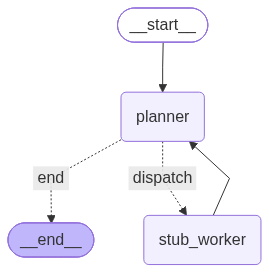

In [3]:
from IPython.display import Image, display

# 2. Extract and draw the graph as a PNG
display(Image(graph.get_graph().draw_mermaid_png()))